# Walmart Retail Sales Analytics — Beginner-Friendly Version

## What this project does

This notebook answers four simple business questions:

1. How do Walmart's weekly sales change over time?
2. Where are negative sales happening?
3. Which forecasting model is most accurate?
4. What sales can Walmart expect during the next 12 weeks?

Every section uses short code cells followed by a plain-English explanation.

## 1. Import the tools

- **pandas** works with tables.
- **NumPy** performs calculations.
- **Matplotlib** creates charts.
- **scikit-learn** builds and evaluates forecasting models.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.tree import DecisionTreeRegressor

plt.style.use("seaborn-v0_8-whitegrid")

/Users/zoolutanwar/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/wb/t7l7142164z_9hnt0m_3myxc0000gn/T/matplotlib-5mg_8w7u because there was an issue with the default path (/Users/zoolutanwar/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Matplotlib is building the font cache; this may take a moment.


## 2. Load the Walmart data

The raw data is stored in `train.csv`. Each row represents one department in one store during one week.

In [2]:
# Find the project folders.
current_folder = Path.cwd().resolve()
project_folder = current_folder.parent if current_folder.name == "notebooks" else current_folder
data_file = project_folder / "data" / "walmart-recruiting-store-sales-forecasting" / "train.csv"
output_folder = project_folder / "outputs"
output_folder.mkdir(exist_ok=True)

# Read the CSV and convert Date into a real date column.
sales = pd.read_csv(data_file)
sales["Date"] = pd.to_datetime(sales["Date"])

print("Number of rows:", f"{len(sales):,}")
display(sales.head())

Number of rows: 421,570


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


### Understanding the columns

- `Store`: store number
- `Dept`: department number
- `Date`: week-ending date
- `Weekly_Sales`: sales for that store and department
- `IsHoliday`: whether the week contains a major holiday

In [3]:
# Check whether important values are missing or duplicated.
print("Missing values in each column:")
display(sales.isna().sum().to_frame("Missing Values"))

print("Duplicate rows:", sales.duplicated().sum())

Missing values in each column:


,Missing Values
Store,0
Dept,0
Date,0
Weekly_Sales,0
IsHoliday,0


Duplicate rows: 0


**Why this matters:** Missing or duplicated rows can make totals and model results unreliable. This check confirms whether cleaning is required before analysis.

## 3. Look at total weekly sales

The raw table has many rows for each date. We add all stores and departments together to obtain Walmart's total sales for each week.

In [4]:
weekly_sales = sales.groupby("Date")["Weekly_Sales"].sum()
weekly_sales = weekly_sales.sort_index()

display(weekly_sales.head().to_frame())

,Weekly_Sales
Date,
2010-02-05,49750740.50
2010-02-12,48336677.63
2010-02-19,48276993.78
2010-02-26,43968571.13
2010-03-05,46871470.30


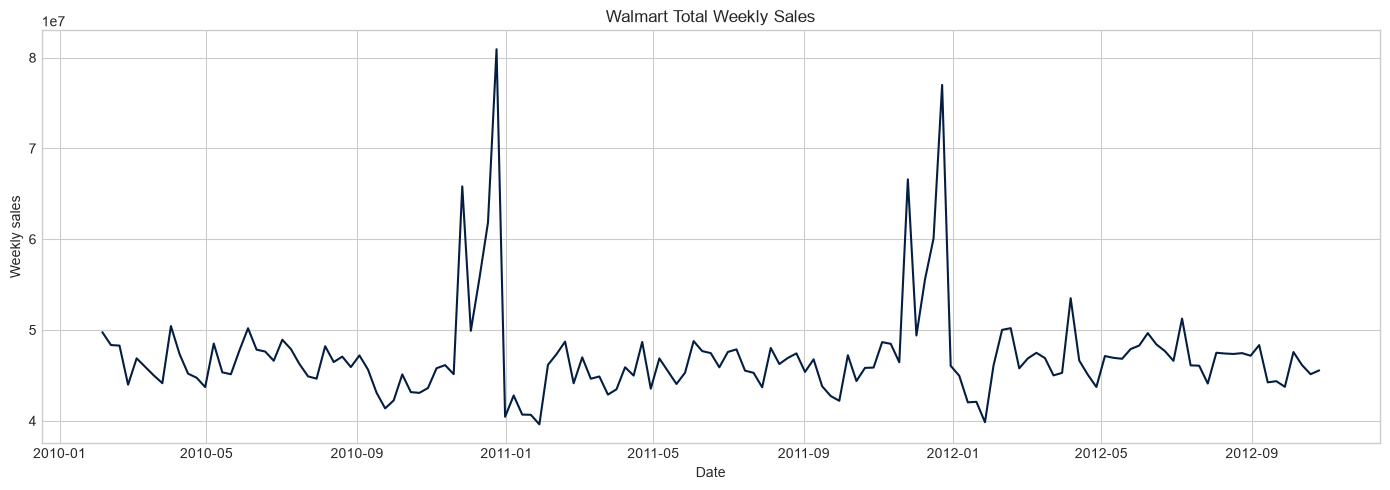

In [5]:
plt.figure(figsize=(14, 5))
plt.plot(weekly_sales.index, weekly_sales.values, color="#041E42")
plt.title("Walmart Total Weekly Sales")
plt.xlabel("Date")
plt.ylabel("Weekly sales")
plt.tight_layout()
plt.savefig(output_folder / "weekly_sales_history.png", dpi=200)
plt.show()

**What the chart tells us:** Normal weekly sales are usually between 40M and 50M. The large repeating peaks occur around Thanksgiving and Christmas, showing strong yearly seasonality.

## 4. Investigate negative sales

Negative sales can represent returns, refunds, accounting adjustments, or data-quality problems.

In [6]:
# Create a True/False column. True means the sale is negative.
sales["Is_Negative"] = sales["Weekly_Sales"] < 0
sales["Negative_Amount"] = sales["Weekly_Sales"].where(sales["Is_Negative"], 0)

negative_rows = sales[sales["Is_Negative"]]
negative_rate = len(negative_rows) / len(sales) * 100

print("Negative records:", f"{len(negative_rows):,}")
print("Percentage of all records:", f"{negative_rate:.2f}%")
print("Total negative value:", f"{negative_rows['Weekly_Sales'].sum():,.2f}")

Negative records: 1,285
Percentage of all records: 0.30%
Total negative value: -88,161.56


### Compare the departments highlighted by the analysis

For each department, we count all records and negative records. The negative-sales rate is:

`negative records ÷ total records × 100`

In [7]:
departments_to_check = [47, 49, 80]
department_data = sales[sales["Dept"].isin(departments_to_check)].copy()

department_summary = department_data.groupby("Dept").agg(
    total_observations=("Weekly_Sales", "count"),
    negative_observations=("Is_Negative", "sum"),
    negative_impact=("Negative_Amount", "sum")
)

department_summary["negative_rate"] = (
    department_summary["negative_observations"]
    / department_summary["total_observations"]
    * 100
)

display(department_summary.round(2))

,total_observations,negative_observations,negative_impact,negative_rate
Dept,,,,
47,646,254,-53188.06,39.32
49,4482,67,-1455.98,1.49
80,5891,68,-4231.48,1.15


### Is Store 35 different from the other stores?

We label every record as either `Store 35` or `Other stores`, then calculate the same negative-sales rate for each group.

In [8]:
department_data["store_group"] = "Other stores"
department_data.loc[department_data["Store"] == 35, "store_group"] = "Store 35"

store_comparison = department_data.groupby(["Dept", "store_group"]).agg(
    total_observations=("Weekly_Sales", "count"),
    negative_observations=("Is_Negative", "sum"),
    negative_impact=("Negative_Amount", "sum")
)

store_comparison["negative_rate"] = (
    store_comparison["negative_observations"]
    / store_comparison["total_observations"]
    * 100
)

display(store_comparison.round(2))

total_observations  negative_observations  negative_impact  \
Dept store_group                                                                
47   Other stores                 610                    234        -47994.91   
     Store 35                      36                     20         -5193.15   
49   Other stores                4425                     47          -895.33   
     Store 35                      57                     20          -560.65   
80   Other stores                5757                     43         -2359.84   
     Store 35                     134                     25         -1871.64   

                   negative_rate  
Dept store_group                  
47   Other stores          38.36  
     Store 35              55.56  
49   Other stores           1.06  
     Store 35              35.09  
80   Other stores           0.75  
     Store 35              18.66

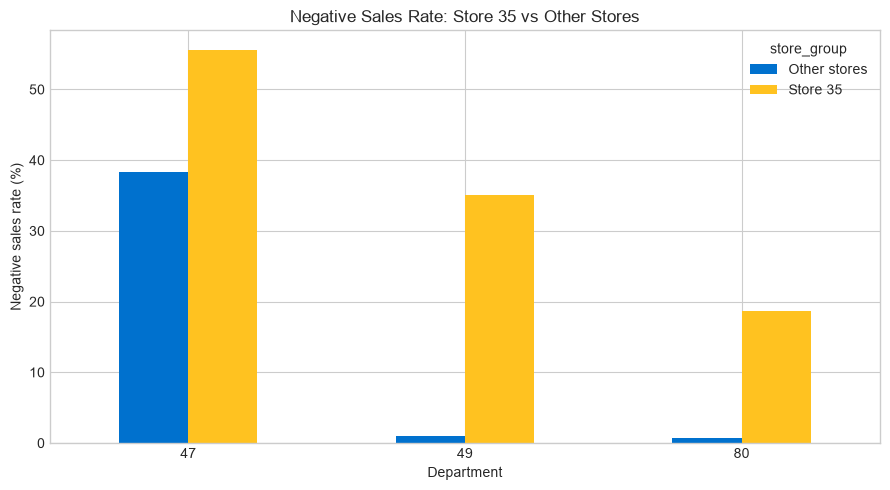

In [9]:
rates_for_chart = store_comparison["negative_rate"].unstack()

rates_for_chart.plot(
    kind="bar",
    figsize=(9, 5),
    color=["#0071CE", "#FFC220"]
)
plt.title("Negative Sales Rate: Store 35 vs Other Stores")
plt.xlabel("Department")
plt.ylabel("Negative sales rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(output_folder / "store35_negative_sales_comparison.png", dpi=200)
plt.show()

**Finding:** Department 47 has negative sales across many stores. Departments 49 and 80 are especially unusual in Store 35, suggesting a store-specific returns, refund, inventory, or data-entry issue.

### How did Department 47 change over time?

In [10]:
department_47 = sales[sales["Dept"] == 47].copy()
department_47["Year"] = department_47["Date"].dt.year

dept47_yearly = department_47.groupby("Year").agg(
    total_observations=("Weekly_Sales", "count"),
    negative_observations=("Is_Negative", "sum"),
    negative_impact=("Negative_Amount", "sum")
)

dept47_yearly["negative_rate"] = (
    dept47_yearly["negative_observations"]
    / dept47_yearly["total_observations"]
    * 100
)

display(dept47_yearly.round(2))

,total_observations,negative_observations,negative_impact,negative_rate
Year,,,,
2010,266,88,-21670.69,33.08
2011,205,86,-20176.10,41.95
2012,175,80,-11341.27,45.71


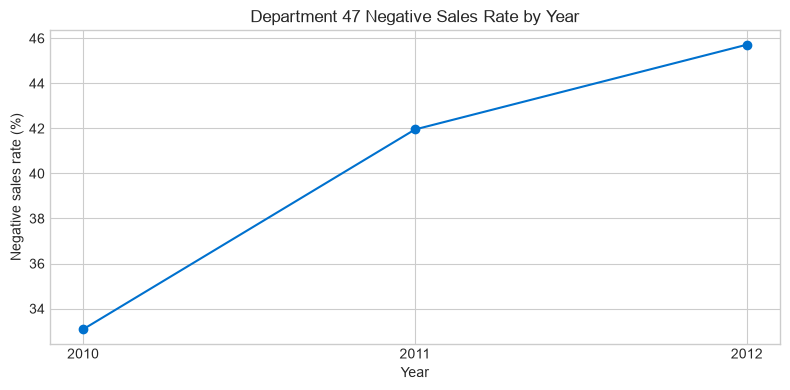

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(
    dept47_yearly.index,
    dept47_yearly["negative_rate"],
    marker="o",
    color="#0071CE"
)
plt.title("Department 47 Negative Sales Rate by Year")
plt.xlabel("Year")
plt.ylabel("Negative sales rate (%)")
plt.xticks(dept47_yearly.index)
plt.tight_layout()
plt.savefig(output_folder / "dept47_yearly_negative_rate.png", dpi=200)
plt.show()

**Finding:** Department 47's negative-sales rate rose from about 33% in 2010 to about 46% in 2012. This deserves a company-wide investigation.

## 5. Prepare the forecasting data

We reserve the final 12 weeks for testing. The models train only on earlier weeks, which prevents them from seeing the future.

In [12]:
# Create simple calendar features for the models.
model_data = weekly_sales.to_frame(name="Weekly_Sales")
model_data["Year"] = model_data.index.year
model_data["Month"] = model_data.index.month
model_data["Week"] = model_data.index.isocalendar().week.astype(int)

# Give the model the sales from the same week one year earlier.
model_data["Last_Year_Sales"] = model_data["Weekly_Sales"].shift(52)
model_data = model_data.dropna()

test_weeks = 12
train_data = model_data.iloc[:-test_weeks]
test_data = model_data.iloc[-test_weeks:]

print("Training weeks:", len(train_data))
print("Testing weeks:", len(test_data))

Training weeks: 79
Testing weeks: 12


The four model inputs are easy to explain: year, month, week number, and sales during the same week last year.

In [13]:
feature_columns = ["Year", "Month", "Week", "Last_Year_Sales"]

X_train = train_data[feature_columns]
y_train = train_data["Weekly_Sales"]
X_test = test_data[feature_columns]
y_test = test_data["Weekly_Sales"]

## 6. Train three models

- **Linear Regression:** finds a simple mathematical relationship.
- **Decision Tree:** makes a series of rule-based splits.
- **Random Forest:** combines many decision trees.
- **Seasonal Baseline:** simply uses last year's sales as the prediction.

In [14]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

tree_model = DecisionTreeRegressor(max_depth=4, random_state=42)
tree_model.fit(X_train, y_train)

forest_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=2,
    random_state=42
)
forest_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of t

## 7. Compare model accuracy

- **MAE:** the average size of the prediction error.
- **RMSE:** similar to MAE but penalises large mistakes more heavily.
- **MAPE:** average error shown as a percentage.

Lower values are better for all three measures.

In [15]:
predictions = {
    "Seasonal Baseline": X_test["Last_Year_Sales"].values,
    "Linear Regression": linear_model.predict(X_test),
    "Decision Tree": tree_model.predict(X_test),
    "Random Forest": forest_model.predict(X_test)
}

result_rows = []

for model_name, predicted_sales in predictions.items():
    mae = mean_absolute_error(y_test, predicted_sales)
    rmse = np.sqrt(mean_squared_error(y_test, predicted_sales))
    mape = np.mean(np.abs((y_test - predicted_sales) / y_test)) * 100

    result_rows.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

model_results = pd.DataFrame(result_rows).sort_values("MAPE")
display(model_results.round(2))

,Model,MAE,RMSE,MAPE
1,Linear Regression,702395.39,890071.31,1.53
3,Random Forest,718644.89,1116383.58,1.57
0,Seasonal Baseline,974641.62,1160987.12,2.12
2,Decision Tree,1103848.91,1360534.49,2.43


**Model choice:** Linear Regression has the lowest MAPE at approximately 1.53%. It is also the easiest model to explain, so it is selected for the final forecast.

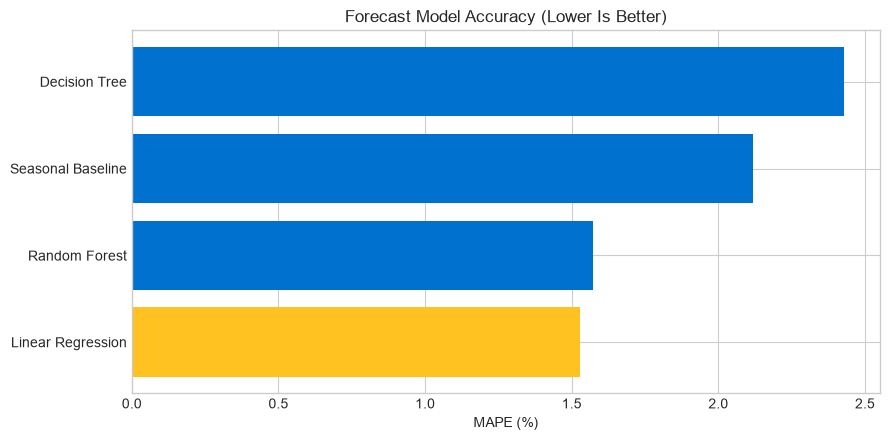

In [16]:
results_for_chart = model_results.sort_values("MAPE", ascending=True)
bar_colors = [
    "#FFC220" if name == "Linear Regression" else "#0071CE"
    for name in results_for_chart["Model"]
]

plt.figure(figsize=(9, 4.5))
plt.barh(results_for_chart["Model"], results_for_chart["MAPE"], color=bar_colors)
plt.title("Forecast Model Accuracy (Lower Is Better)")
plt.xlabel("MAPE (%)")
plt.tight_layout()
plt.savefig(output_folder / "model_comparison.png", dpi=200)
plt.show()

## 8. Forecast the next 12 weeks

First, retrain Linear Regression using all available historical weeks. Then create the same four inputs for 12 future dates.

In [17]:
final_model = LinearRegression()
final_model.fit(model_data[feature_columns], model_data["Weekly_Sales"])

future_dates = pd.date_range(
    start=weekly_sales.index.max() + pd.Timedelta(weeks=1),
    periods=12,
    freq="W-FRI"
)

future_inputs = pd.DataFrame(index=future_dates)
future_inputs["Year"] = future_inputs.index.year
future_inputs["Month"] = future_inputs.index.month
future_inputs["Week"] = future_inputs.index.isocalendar().week.astype(int)
future_inputs["Last_Year_Sales"] = [
    weekly_sales.loc[date - pd.Timedelta(weeks=52)]
    for date in future_dates
]

future_forecast = pd.DataFrame({
    "Date": future_dates,
    "Predicted_Weekly_Sales": final_model.predict(future_inputs)
})

display(future_forecast.round(2))

/var/folders/wb/t7l7142164z_9hnt0m_3myxc0000gn/T/ipykernel_2143/432526593.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(future_forecast.round(2))


,Date,Predicted_Weekly_Sales
0,2012-11-02,49331667.16
1,2012-11-09,49210696.38
2,2012-11-16,47568607.88
3,2012-11-23,64132978.23
4,2012-11-30,50045930.68
5,2012-12-07,55142897.67
6,2012-12-14,58883021.72
7,2012-12-21,72787313.98
8,2012-12-28,47416353.89
9,2013-01-04,45037320.42


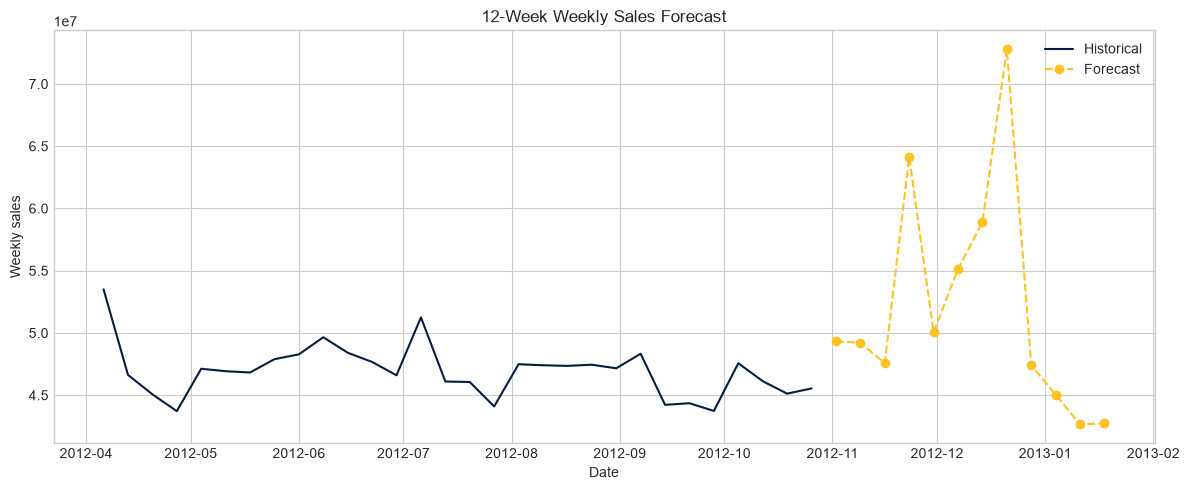

In [18]:
plt.figure(figsize=(12, 5))
plt.plot(weekly_sales.tail(30), label="Historical", color="#041E42")
plt.plot(
    future_forecast["Date"],
    future_forecast["Predicted_Weekly_Sales"],
    marker="o",
    linestyle="--",
    label="Forecast",
    color="#FFC220"
)
plt.title("12-Week Weekly Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Weekly sales")
plt.legend()
plt.tight_layout()
plt.savefig(output_folder / "future_12_week_forecast.png", dpi=200)
plt.show()

**Forecast interpretation:** The model predicts the expected Thanksgiving and Christmas peaks, followed by the usual post-holiday decline.

## 9. Export clean files for Power BI

This final cell saves the tables used by the dashboard. It does not change the analysis.

In [19]:
historical_table = weekly_sales.reset_index(name="Weekly_Sales")
historical_table["Data_Type"] = "Historical"

forecast_table = future_forecast.rename(
    columns={"Predicted_Weekly_Sales": "Weekly_Sales"}
)
forecast_table["Data_Type"] = "Forecast"

powerbi_sales = pd.concat([historical_table, forecast_table], ignore_index=True)

department_summary.round(2).to_csv(output_folder / "department_summary.csv")
store_comparison.round(2).to_csv(output_folder / "store35_vs_other_stores.csv")
dept47_yearly.round(2).to_csv(output_folder / "dept47_yearly_summary.csv")
model_results.to_csv(output_folder / "model_comparison.csv", index=False)
future_forecast.to_csv(output_folder / "future_12_week_forecast.csv", index=False)
powerbi_sales.to_csv(output_folder / "powerbi_sales_forecast.csv", index=False)

with pd.ExcelWriter(output_folder / "walmart_powerbi_dashboard.xlsx") as writer:
    powerbi_sales.to_excel(writer, sheet_name="Sales_Forecast", index=False)
    model_results.to_excel(writer, sheet_name="Model_Results", index=False)
    store_comparison.reset_index().to_excel(writer, sheet_name="Negative_Sales", index=False)
    dept47_yearly.reset_index().to_excel(writer, sheet_name="Dept47_Yearly", index=False)

print("Finished. Dashboard files were saved in the outputs folder.")

Finished. Dashboard files were saved in the outputs folder.


## 10. Final business conclusions

1. Walmart sales show clear Thanksgiving and Christmas seasonality.
2. Department 47 has a widespread negative-sales issue.
3. Store 35 needs a focused review of Departments 49 and 80.
4. Linear Regression produced the best test accuracy with about 1.53% MAPE.
5. The forecast can support short-term inventory and staffing decisions.

### Important limitation

Negative sales may be valid returns or accounting corrections. The dataset does not include transaction reasons, so the analysis identifies where to investigate but cannot prove the exact cause.